In [1]:
%matplotlib inline 

In [2]:
import os
import io
import re
import pandas as pd
import json

In [48]:
#work_fldr = r'D:\Users\Work\OneDrive - Transport Systems Catapult\Research\PhD\Models\tripchains_from_od'
#work_fldr = r'C:\Users\haris.ballis\OneDrive - Transport Systems Catapult\Research\PhD\Programming\tcs_od'
#work_fldr = r'C:\Users\Work\Desktop\local_optimisation\tripchains_from_od'
#work_fldr = r'/mnt/sda1/Users/Linux/OneDrive/PhD/Models/tcs_od'
work_fldr = r'C:\Users\haris.ballis\Desktop\local_cplex_run\tcs_od'

data_source = 'mnd_TSC'
model_name = 'sample_1000'
trips_direction = 'internalToInternal'
distr_contr_enabled_switch = [True, False]

tolerance = 0.01
out_folder = os.path.join(work_fldr, r'generation/outputs', r'{}/{}/{}'.format(data_source, model_name, trips_direction))

In [49]:
def prepare_results_filepaths(run_results_fldr):

    paths = dict()
    paths['od'] = os.path.join(run_results_fldr, 'od_filtered.csv')
    paths['tours_mdl_descr'] = os.path.join(run_results_fldr, 'tours_mdl_descr.csv')
    paths['tours_mdl_info'] = os.path.join(run_results_fldr, 'tours_mdl_info.csv')
    paths['observed_distribution'] = os.path.join(run_results_fldr, 'target_distribution.csv')
    paths['optimisation_results'] = os.path.join(run_results_fldr, 'results.json')

    return paths

In [50]:
def get_optimisation_results(infilepath):
    with open(infilepath) as f:
        data = json.load(f)

        results = data['Solution'][1]['Variable']

        df_data = list()
        for chain, val in results.items():
            cid = re.search('\[(\d+)\]', chain, re.DOTALL).group(1)
            times_used = val['Value']
            df_data.append([int(cid), times_used])

        df = pd.DataFrame(df_data, columns=['TripChainId', 'TimesUsed']).set_index('TripChainId').squeeze()
        return df

In [51]:
def convert_optimisation_output_to_trips(tcs_descr, optim_output):
    # Calculate how many times the tripchain has been used by the optimiser 
    df = tcs_descr.join(optim_output, how='right')
    grpby_cols = ['OrigZoneId', 'DestZoneId', 'Purpose', 'TimePeriod']
    optimisation_trips = df.groupby(grpby_cols)['TimesUsed'].sum().squeeze()
    optimisation_trips.name = 'OptimisationTrips'
    return optimisation_trips


In [52]:
def get_modelled_trips(paths):
    
    tcs_descr = pd.read_csv(paths['tours_mdl_descr'], index_col=['TripChainId'])
    optim_output = get_optimisation_results(paths['optimisation_results'])
    
    if optim_output is not None:
        optimisation_trips = convert_optimisation_output_to_trips(tcs_descr, optim_output)
        return optimisation_trips, optim_output
    else:
        return None

In [53]:
def include_run_info(df, legs, trips_thresh, distr_constr_enabled):
    try:
        df = df.to_frame()
    except AttributeError:
        pass
    
    df['MaxLegs'] = int(legs)
    df['TripsThresh'] = int(trips_thresh)
    df['DistrConstr'] = distr_constr_enabled
    df.set_index(['MaxLegs', 'TripsThresh', 'DistrConstr'], append=True, inplace=True)
    df = df.squeeze()
    
    return df

In [54]:
def prepare_ods_comparison(optim_ods, init_ods):
    comp = init_ods.to_frame().join(optim_ods)
    comp.columns.name = 'TripsSource'
    comp = comp.stack()
    comp.name = 'Trips'
    return comp

In [55]:
def get_input_params_from_folder(infldr):
    fldrs = [name for name in os.listdir(infldr) if os.path.isdir(os.path.join(infldr, name))]
    inputs = []
    for fldr in fldrs:
        matches = re.findall('(\d+)legs-over(\d+)trips-distrConstr(\w+)', fldr)
        if matches:
            legs = int(matches[0][0])
            trips = int(matches[0][1])
            if matches[0][2] == 'True':
                distr_constr_enabled = True
            elif matches[0][2] == 'False':
                distr_constr_enabled = False
            else:
                raise ValueError('distrConstrEnabled must be either True or False')
                
            inputs.append([legs, trips, distr_constr_enabled])
        
    return inputs

In [56]:
def prepare_ditribution_comparison(fldrpaths):
    tcs_info = pd.read_csv(fldrpaths['tours_mdl_info'], index_col=['TripChainId'])
    optim_output = get_optimisation_results(fldrpaths['optimisation_results'])
    observed_distr = pd.read_csv(fldrpaths['observed_distribution'], index_col='DistrGroupId')
    observed_distr.drop(columns=['Size'], inplace=True)

    df = tcs_info.join(optim_output, how='right')
    optim_distr = df.groupby('DistrGroupId')['TimesUsed'].sum()
    optim_distr = optim_distr.div(optim_distr.sum())
    optim_distr.name = 'Percentage'
    
    # We need to identify the distribution dimensions cols (should be all apart form the Percentage)
    idx_cols = list()
    for c in observed_distr.columns:
        if c != 'Percentage':
            idx_cols.append(c)
    
    observed_distr.set_index(idx_cols, append=True, inplace=True)
    observed_distr = observed_distr.squeeze()
    
    distr_comp = observed_distr.to_frame().join(optim_distr, rsuffix='_')
    distr_comp.columns = ['Observed', 'Estimated']
    distr_comp.columns.name = 'Source'
    distr_comp = distr_comp.stack()
    distr_comp.name = 'Percentage'

    return distr_comp

In [57]:
def collapse_tour_legs(tours, leg_descr_cols):
    seqs = list()
    for c in leg_descr_cols:
        seq = tours.groupby('TripChainId')[c].apply(tuple)
        seqs.append(seq)
    
    tours_collapsed = pd.concat(seqs, axis=1)
    
    return tours_collapsed

In [58]:
def prepare_descr_comparison(flpaths, mdl_nchains):
    tours_obs = pd.read_csv(flpaths['tours_obs_descr'], index_col=[0, 1])
    tours_mdl = pd.read_csv(flpaths['tours_mdl_descr'], index_col=[0, 1])

    # Standardising frames
    cmn_idx_names = ['TripChainId', 'LegSeqIdx']
    tours_obs.index.names = cmn_idx_names
    tours_mdl.index.names = cmn_idx_names

    # Kepp only the used tripchains
    tours_mdl = tours_mdl.loc[tours_mdl.index]
    
    # Split Purpose in purpose and direction
    tours_mdl['Purpose'], tours_mdl['Direction'] = tours_mdl['Purpose'].str.split('_', 1).str

    leg_descr_cols = ['OrigZoneId', 'DestZoneId', 'Purpose', 'Direction', 'TimePeriod']

    tours_obs_clpsd = collapse_tour_legs(tours_obs, leg_descr_cols)
    tours_mdl_clpsd = collapse_tour_legs(tours_mdl, leg_descr_cols)

    comp = pd.merge(tours_obs_clpsd.reset_index(), tours_mdl_clpsd.reset_index(),
                on=leg_descr_cols, how='outer', suffixes=('_obs', '_mdl'),
                indicator='Exist')
    
    comp.drop(columns=leg_descr_cols, inplace=True)
    comp = comp.squeeze()

    comp['Exist'] = comp['Exist'].str.replace('left_only', 'obs_only')
    comp['Exist'] = comp['Exist'].str.replace('right_only', 'mdl_only')

    return comp

In [59]:
##### MAIN
generation_inputs_fldr = os.path.join(work_fldr, r'generation/inputs/{}/{}/{}'.format(data_source, model_name, trips_direction))
inputs = get_input_params_from_folder(results_fldr)

concat_mdl_od = list()
concat_mdl_nchains = list()
concat_obs_ods = list()
concat_comp_distrs = list()
concat_comp_descrs = list()

for legs, trips_thresh, distr_constr_enabled in inputs:

    run_tmplt = '{}legs-over{}trips-distrConstr{}'.format(legs, trips_thresh, distr_constr_enabled)
    run_results_fldr = os.path.join(results_fldr, run_tmplt)
    
    flpaths = prepare_results_filepaths(run_results_fldr)
    flpaths['tours_obs_descr'] = os.path.join(generation_inputs_fldr, 'obs_tours_descr.csv')
    flpaths['tours_obs_info'] = os.path.join(generation_inputs_fldr, 'obs_tours_info.csv')
    
    mdl_od, mdl_nchains = get_modelled_trips(flpaths)
    
    if mdl_od is None:
        print('No results for legs:{}-trips:{}-distrConstr:{}'.format(legs, trips_thresh, distr_constr_enabled))
        continue
    
    comp_distr = prepare_ditribution_comparison(flpaths)
    comp_descr = prepare_descr_comparison(flpaths, mdl_nchains)
    
    idx_cols_od = ['OrigZoneId', 'DestZoneId', 'Purpose', 'TimePeriod']
    obs_od = pd.read_csv(flpaths['od'], index_col=idx_cols_od)
    obs_od.drop(columns=['LegId'], inplace=True)
    
    obs_od = include_run_info(obs_od, legs, trips_thresh, distr_constr_enabled)
    mdl_od = include_run_info(mdl_od, legs, trips_thresh, distr_constr_enabled)
    mdl_nchains = include_run_info(mdl_nchains, legs, trips_thresh, distr_constr_enabled)
    comp_distr = include_run_info(comp_distr, legs, trips_thresh, distr_constr_enabled)
    comp_descr = include_run_info(comp_descr, legs, trips_thresh, distr_constr_enabled)
    
    concat_mdl_od.append(mdl_od)
    concat_obs_ods.append(obs_od)
    concat_mdl_nchains.append(mdl_nchains)
    concat_comp_descrs.append(comp_descr)
    concat_comp_distrs.append(comp_distr)
    
mdl_nchains = pd.concat(concat_mdl_nchains)

ods_mdl = pd.concat(concat_mdl_od)
ods_obs = pd.concat(concat_obs_ods)

comp_ods = prepare_ods_comparison(ods_mdl, ods_obs)
comp_distrs = pd.concat(concat_comp_distrs)
comp_descrs = pd.concat(concat_comp_descrs)


In [62]:
mdl_nchains.to_csv(os.path.join(out_folder, 'optimisation_results.csv'), header=True, index=True)
comp_distrs.to_csv(os.path.join(out_folder, 'comparison_distributions.csv'), header=True, index=True)
comp_ods.to_csv(os.path.join(out_folder, 'comparison_od.csv'), header=True)
comp_descrs.to_csv(os.path.join(out_folder, 'comparison_descrs.csv'), header=True, index=True)

In [63]:
df = comp_distrs.copy()
df = df.xs(True, level='DistrConstr')
df = df.unstack('Source')
df['Diff_perc'] = df.Observed.sub(df.Estimated)


df['BelowTolerance'] = df.Diff_perc.abs() <= tolerance
df['BelowTolerance'].all()

True

In [64]:
df = comp_ods.groupby(level=['MaxLegs', 'TripsThresh', 'DistrConstr', 'TripsSource', 'Purpose']).sum()

df = df.unstack('TripsSource')

df['Diff'] = df.DailyTrips - df.OptimisationTrips
df['Diff_perc'] = df.OptimisationTrips/df.DailyTrips - 1

df.style.format({
    'OptimisationTrips': '{:,.0f}'.format,
    'DailyTrips': '{:,.0f}'.format,
    'Diff': '{:,.0f}'.format,
    'Diff_perc': '{:.0%}'.format
})

In [66]:
mdl_nchains.groupby(level=[1,2,3]).sum()

MaxLegs  TripsThresh  DistrConstr
3        1            False          983.0
                      True           983.0
4        1            False          989.0
                      True           989.0
5        1            False          989.0
                      True           989.0
Name: TimesUsed, dtype: float64

(3, 1, False)
(3, 1, True)
(4, 1, False)
(4, 1, True)
(5, 1, False)
(5, 1, True)


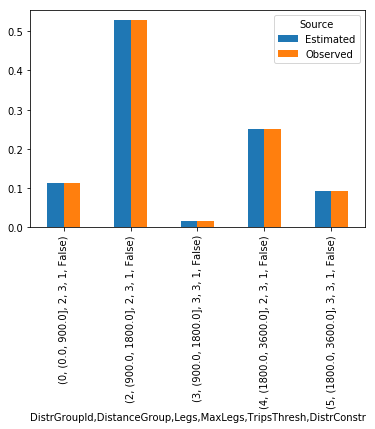

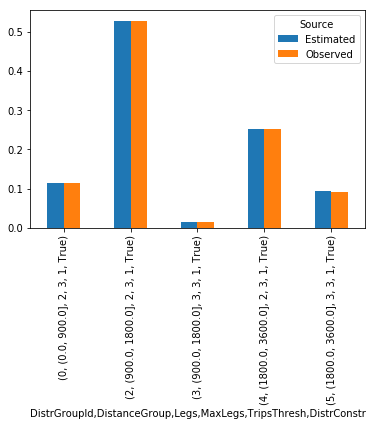

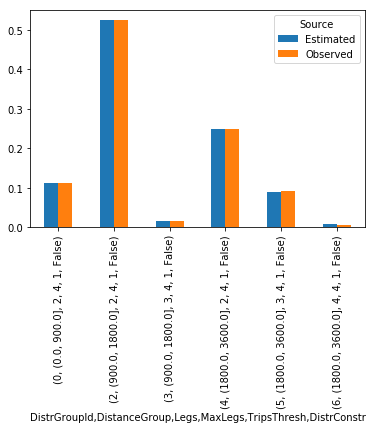

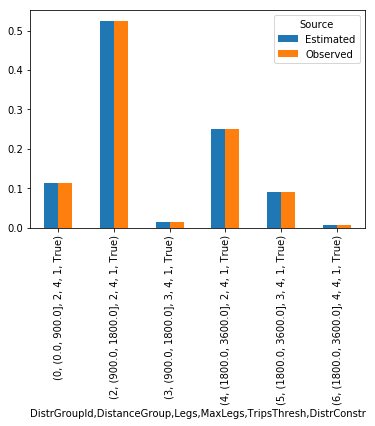

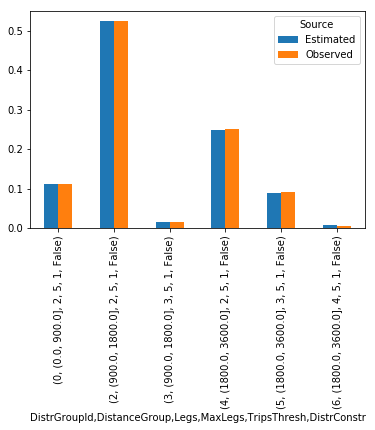

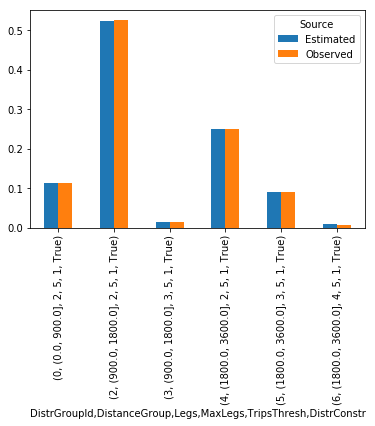

In [67]:
dfg = comp_distrs.groupby(level=['MaxLegs', 'TripsThresh', 'DistrConstr'])
for k, g in dfg:
    print(k)
    plt = g.unstack('Source')
    plt.plot(kind='bar')